In [1]:
# 05 - Model Evaluation & Validation

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load trained model and test data

lgbm_model = joblib.load("../models/lightgbm_model.pkl")

X_test = joblib.load("../models/X_test.pkl")
y_test = joblib.load("../models/y_test.pkl")
test_data = joblib.load("../models/test_data.pkl")

print("Model and test data loaded successfully!")

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("test_data shape:", test_data.shape)

Model and test data loaded successfully!
X_test shape: (19995, 17)
y_test shape: (19995,)
test_data shape: (19995, 20)


/opt/anaconda3/envs/fraud_eval/lib/python3.12/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.5.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [3]:
# Generate fraud probabilities

y_prob = lgbm_model.predict_proba(X_test)[:, 1]

# Apply selected threshold
THRESHOLD = 0.95

y_pred = (y_prob >= THRESHOLD).astype(int)

print("Predictions generated successfully!")
print("Threshold:", THRESHOLD)

Predictions generated successfully!
Threshold: 0.95


In [4]:
# Classification Report

print("LIGHTGBM CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Fraud"],
        digits=4
    )
)

LIGHTGBM CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9969    0.9990    0.9979     19696
       Fraud     0.9222    0.7926    0.8525       299

    accuracy                         0.9959     19995
   macro avg     0.9595    0.8958    0.9252     19995
weighted avg     0.9957    0.9959    0.9957     19995



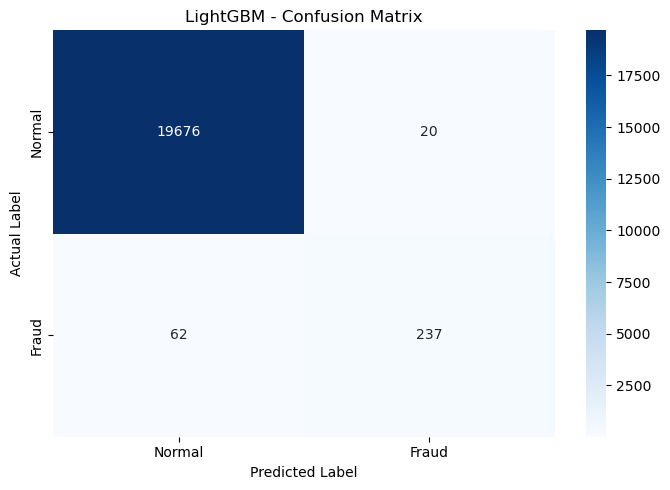

In [5]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.title("LightGBM - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [6]:
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

print(f"ROC-AUC: {roc_auc:.6f}")
print(f"PR-AUC: {pr_auc:.6f}")

ROC-AUC: 0.998754
PR-AUC: 0.937661


In [7]:
# Load original transaction dataset
all_transactions = pd.read_csv(
    "../data/processed/all_transactions.csv"
)

print("Dataset shape:", all_transactions.shape)
print("Columns:", all_transactions.columns.tolist())

Dataset shape: (99975, 12)
Columns: ['transaction_id', 'timestamp', 'sender_id', 'receiver_id', 'transaction_type', 'amount', 'sender_balance_before', 'sender_balance_after', 'device_id', 'location', 'is_fraud', 'fraud_scenario']


In [8]:
# Verify index alignment
print("X_test index range:", X_test.index.min(), "-", X_test.index.max())
print("Original dataset shape:", all_transactions.shape)

print(
    "Index alignment:",
    X_test.index.equals(all_transactions.loc[X_test.index].index)
)

X_test index range: 79980 - 99974
Original dataset shape: (99975, 12)
Index alignment: True


In [9]:
# Prepare scenario-based evaluation dataset

scenario_test = pd.DataFrame({
    "actual": np.asarray(y_test),
    "predicted": y_pred,
    "fraud_probability": y_prob,
    "fraud_scenario": all_transactions.loc[
        X_test.index, "fraud_scenario"
    ].values
})

print("Scenario evaluation dataset:", scenario_test.shape)

display(scenario_test.head())

Scenario evaluation dataset: (19995, 4)


,actual,predicted,fraud_probability,fraud_scenario
0,0,0,4.984446e-07,NORMAL
1,0,0,1.261903e-07,NORMAL
2,0,0,1.544520e-07,NORMAL
3,0,0,1.084182e-06,NORMAL
4,0,0,1.867453e-07,NORMAL


In [10]:
# Filter fraud transactions only
fraud_scenarios = scenario_test[
    scenario_test["fraud_scenario"] != "NORMAL"
].copy()

scenario_results = []

for scenario, group in fraud_scenarios.groupby("fraud_scenario"):

    actual = group["actual"]
    predicted = group["predicted"]

    tp = ((actual == 1) & (predicted == 1)).sum()
    fn = ((actual == 1) & (predicted == 0)).sum()
    fp = ((actual == 0) & (predicted == 1)).sum()

    scenario_results.append({
        "scenario": scenario,
        "total_transactions": len(group),
        "actual_fraud": int((actual == 1).sum()),
        "detected_fraud": int(tp),
        "missed_fraud": int(fn),
        "false_alerts": int(fp),
        "precision": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "f1_score": f1_score(actual, predicted, zero_division=0)
    })

scenario_results_df = pd.DataFrame(scenario_results)

scenario_results_df = scenario_results_df.sort_values(
    "recall",
    ascending=False
)

display(
    scenario_results_df.round(4)
)

,scenario,total_transactions,actual_fraud,detected_fraud,missed_fraud,false_alerts,precision,recall,f1_score
4,UNUSUAL_AMOUNT,55,55,54,1,0,1.0,0.9818,0.9908
0,ACCOUNT_TAKEOVER,104,104,92,12,0,1.0,0.8846,0.9388
3,RAPID_TRANSACTIONS,40,40,34,6,0,1.0,0.8500,0.9189
2,MONEY_LAUNDERING,60,60,42,18,0,1.0,0.7000,0.8235
1,COORDINATED_FRAUD,40,40,15,25,0,1.0,0.3750,0.5455


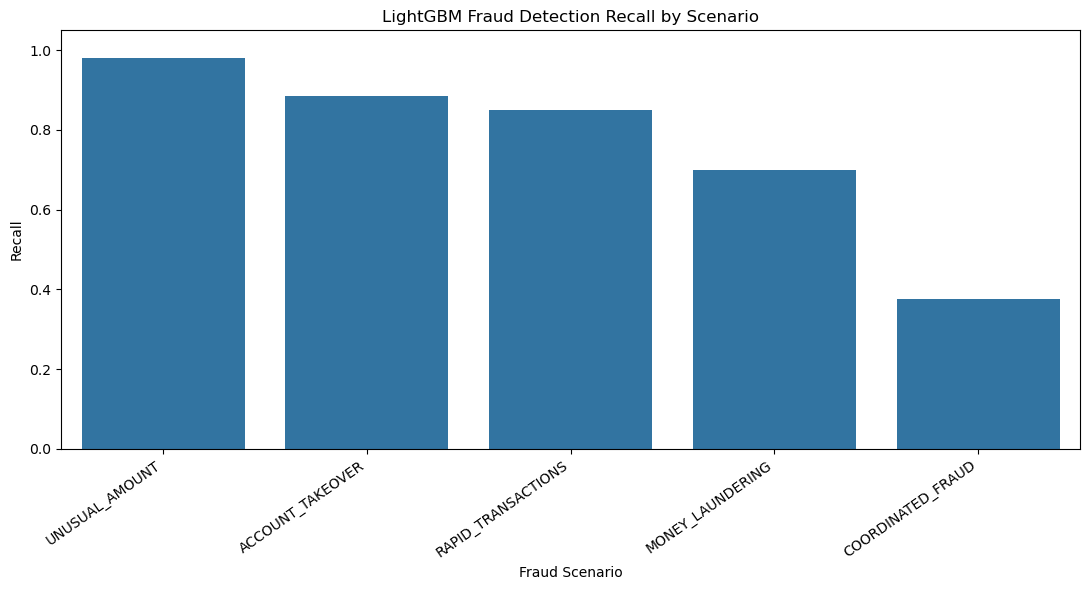

In [11]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=scenario_results_df,
    x="scenario",
    y="recall"
)

plt.title("LightGBM Fraud Detection Recall by Scenario")
plt.xlabel("Fraud Scenario")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

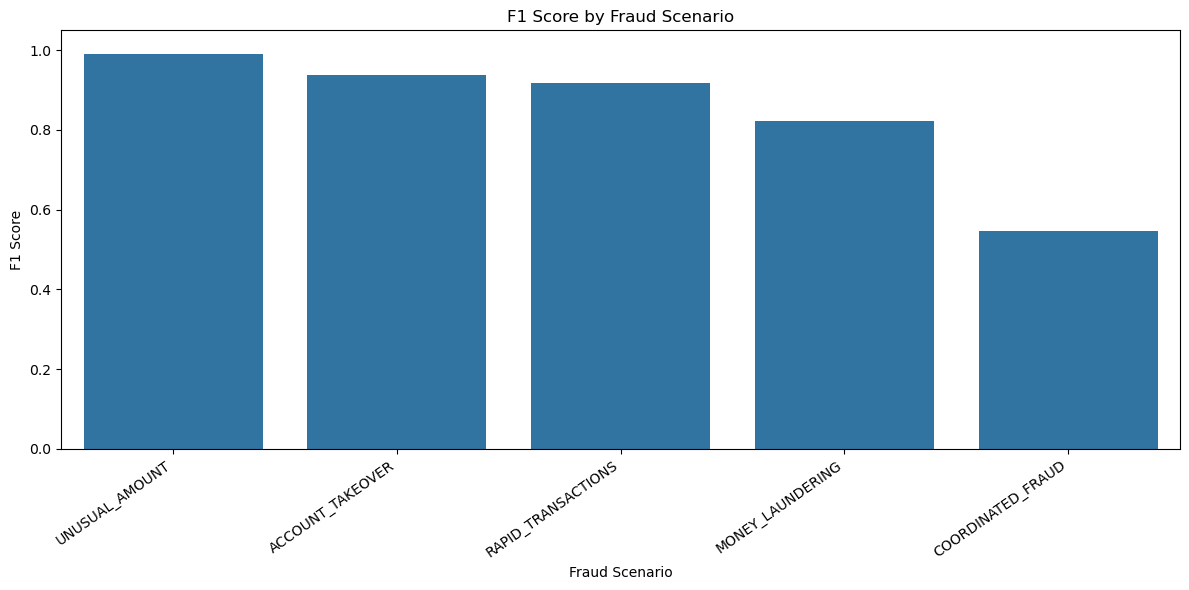

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=scenario_results_df,
    x="scenario",
    y="f1_score"
)

plt.title("F1 Score by Fraud Scenario")
plt.xlabel("Fraud Scenario")
plt.ylabel("F1 Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

In [13]:
error_analysis = scenario_test.copy()

error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual"] == 1) & (error_analysis["predicted"] == 0),
        (error_analysis["actual"] == 0) & (error_analysis["predicted"] == 1)
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct Prediction"
)

print(error_analysis["error_type"].value_counts())

error_type
Correct Prediction    19913
False Negative           62
False Positive           20
Name: count, dtype: int64


In [14]:
false_positives = error_analysis[
    error_analysis["error_type"] == "False Positive"
].copy()

print("False Positive Count:", len(false_positives))

display(
    false_positives.sort_values(
        "fraud_probability",
        ascending=False
    ).head(20)
)

False Positive Count: 20


,actual,predicted,fraud_probability,fraud_scenario,error_type
10878,0,1,0.999764,NORMAL,False Positive
5785,0,1,0.999666,NORMAL,False Positive
11359,0,1,0.999278,NORMAL,False Positive
15086,0,1,0.999174,NORMAL,False Positive
3780,0,1,0.999015,NORMAL,False Positive
12600,0,1,0.997393,NORMAL,False Positive
17956,0,1,0.996733,NORMAL,False Positive
10138,0,1,0.995330,NORMAL,False Positive
8222,0,1,0.995124,NORMAL,False Positive
496,0,1,0.993314,NORMAL,False Positive


In [15]:
false_negatives = error_analysis[
    error_analysis["error_type"] == "False Negative"
].copy()

print("False Negative Count:", len(false_negatives))

display(
    false_negatives.sort_values(
        "fraud_probability",
        ascending=False
    ).head(20)
)

False Negative Count: 62


,actual,predicted,fraud_probability,fraud_scenario,error_type
787,1,0,0.949745,ACCOUNT_TAKEOVER,False Negative
15113,1,0,0.948180,ACCOUNT_TAKEOVER,False Negative
17502,1,0,0.938435,MONEY_LAUNDERING,False Negative
12967,1,0,0.935220,MONEY_LAUNDERING,False Negative
12947,1,0,0.926383,MONEY_LAUNDERING,False Negative
3505,1,0,0.914483,ACCOUNT_TAKEOVER,False Negative
1426,1,0,0.914266,MONEY_LAUNDERING,False Negative
12096,1,0,0.906625,ACCOUNT_TAKEOVER,False Negative
7094,1,0,0.896551,COORDINATED_FRAUD,False Negative
4849,1,0,0.891174,MONEY_LAUNDERING,False Negative


error_type,False Negative,False Positive
fraud_scenario,,
ACCOUNT_TAKEOVER,12,0
COORDINATED_FRAUD,25,0
MONEY_LAUNDERING,18,0
NORMAL,0,20
RAPID_TRANSACTIONS,6,0
UNUSUAL_AMOUNT,1,0


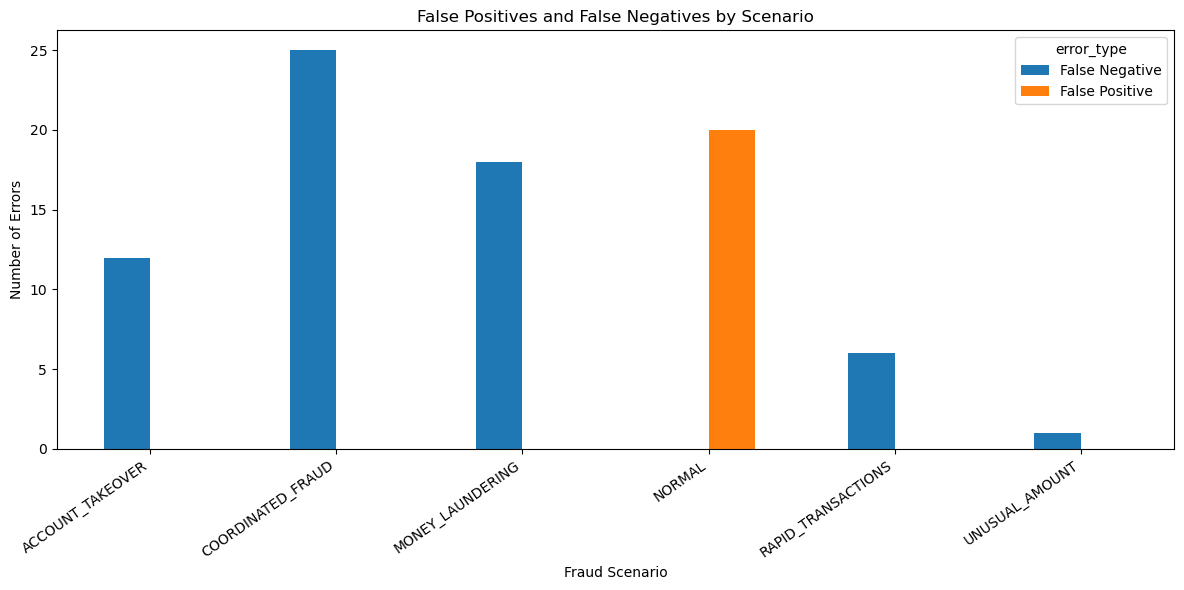

In [16]:
error_distribution = (
    error_analysis[
        error_analysis["error_type"].isin(
            ["False Positive", "False Negative"]
        )
    ]
    .groupby(["fraud_scenario", "error_type"])
    .size()
    .unstack(fill_value=0)
)

display(error_distribution)

error_distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("False Positives and False Negatives by Scenario")
plt.xlabel("Fraud Scenario")
plt.ylabel("Number of Errors")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

X_train_original = joblib.load("../models/X_train.pkl")

In [18]:
from sklearn.impute import SimpleImputer
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

X_train_original = joblib.load("../models/X_train.pkl")
y_train_original = joblib.load("../models/y_train.pkl")

print("X_train:", X_train_original.shape)
print("y_train:", y_train_original.shape)

X_train: (79980, 17)
y_train: (79980,)


In [19]:
feature_to_remove = "transaction_type_code"

X_train_ablation = X_train_original.drop(columns=[feature_to_remove])
X_test_ablation = X_test.drop(columns=[feature_to_remove])

print("Feature removed:", feature_to_remove)
print("X_train ablation:", X_train_ablation.shape)
print("X_test ablation:", X_test_ablation.shape)

Feature removed: transaction_type_code
X_train ablation: (79980, 16)
X_test ablation: (19995, 16)


In [20]:
original_params = {
    "n_estimators": 300,
    "learning_rate": 0.05,
    "max_depth": -1,
    "num_leaves": 31,
    "random_state": 42,
    "class_weight": "balanced",
    "verbosity": -1
}

print("Ablation model parameters defined.")

Ablation model parameters defined.


In [21]:
ablation_lgbm = LGBMClassifier(**original_params)

ablation_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", ablation_lgbm)
])

ablation_model.fit(X_train_ablation, y_train_original)

print("Ablation model trained successfully!")

Ablation model trained successfully!


In [22]:
# Rebuild temporal test dataset

temporal_test = scenario_test.copy()

timestamp_raw = all_transactions.loc[X_test.index, "timestamp"]

temporal_test["timestamp"] = pd.to_datetime(
    timestamp_raw.astype(str),
    format="mixed",
    errors="coerce"
).values

temporal_test["month"] = temporal_test["timestamp"].dt.to_period("M")

print("Valid timestamps:", temporal_test["timestamp"].notna().sum())
print("Missing timestamps:", temporal_test["timestamp"].isna().sum())

display(
    temporal_test.groupby("month").agg(
        total_transactions=("month", "count"),
        actual_fraud=("actual", "sum"),
        detected_fraud=("predicted", "sum")
    )
)

Valid timestamps: 19995
Missing timestamps: 0


,total_transactions,actual_fraud,detected_fraud
month,,,
2026-01,19995,299,257


In [23]:
monthly_results = []

for month, group in temporal_test.dropna(subset=["month"]).groupby("month"):

    actual = group["actual"]
    predicted = group["predicted"]

    monthly_results.append({
        "month": str(month),
        "transactions": len(group),
        "fraud_count": int(actual.sum()),
        "detected_fraud": int(((actual == 1) & (predicted == 1)).sum()),
        "missed_fraud": int(((actual == 1) & (predicted == 0)).sum()),
        "recall": recall_score(actual, predicted, zero_division=0)
    })

monthly_results_df = pd.DataFrame(monthly_results)

display(monthly_results_df.round(4))

,month,transactions,fraud_count,detected_fraud,missed_fraud,recall
0,2026-01,19995,299,237,62,0.7926


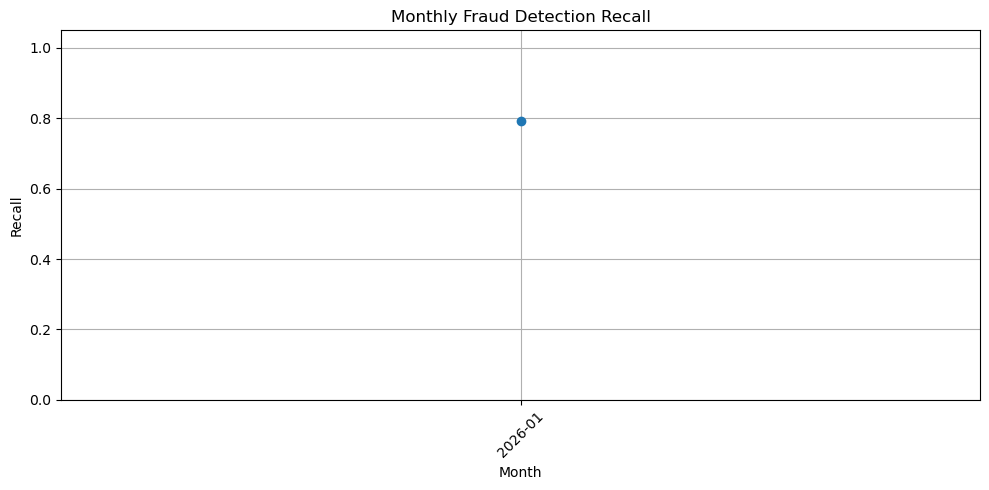

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_results_df["month"],
    monthly_results_df["recall"],
    marker="o"
)

plt.title("Monthly Fraud Detection Recall")
plt.xlabel("Month")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

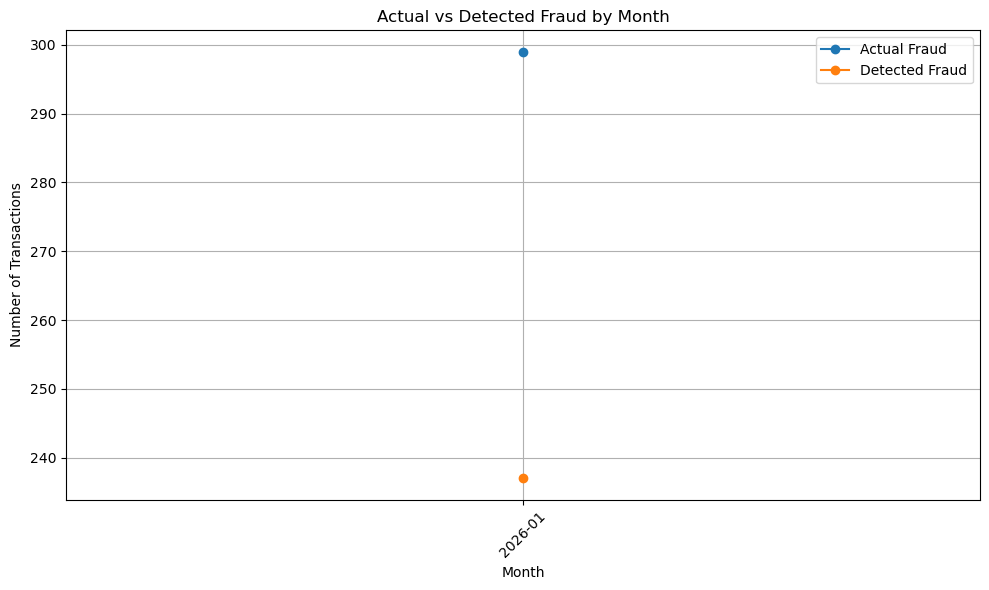

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    monthly_results_df["month"],
    monthly_results_df["fraud_count"],
    marker="o",
    label="Actual Fraud"
)

plt.plot(
    monthly_results_df["month"],
    monthly_results_df["detected_fraud"],
    marker="o",
    label="Detected Fraud"
)

plt.title("Actual vs Detected Fraud by Month")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

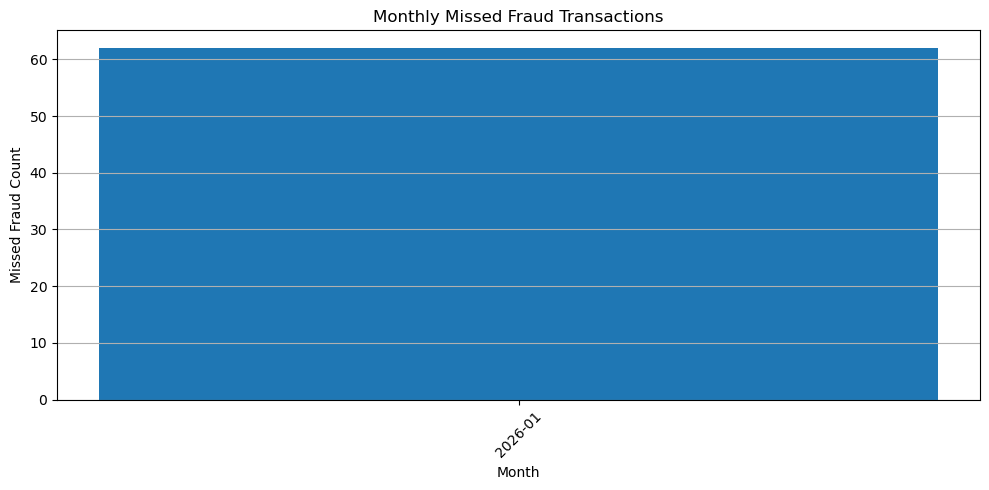

In [26]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_results_df["month"],
    monthly_results_df["missed_fraud"]
)

plt.title("Monthly Missed Fraud Transactions")
plt.xlabel("Month")
plt.ylabel("Missed Fraud Count")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [27]:
daily_test = temporal_test.dropna(subset=["timestamp"]).copy()

daily_test["date"] = daily_test["timestamp"].dt.date

daily_results = []

for date, group in daily_test.groupby("date"):

    actual = group["actual"]
    predicted = group["predicted"]

    daily_results.append({
        "date": str(date),
        "transactions": len(group),
        "actual_fraud": int(actual.sum()),
        "detected_fraud": int(((actual == 1) & (predicted == 1)).sum()),
        "missed_fraud": int(((actual == 1) & (predicted == 0)).sum()),
        "recall": recall_score(actual, predicted, zero_division=0)
    })

daily_results_df = pd.DataFrame(daily_results)

display(daily_results_df.round(4))

,date,transactions,actual_fraud,detected_fraud,missed_fraud,recall
0,2026-01-24,93,0,0,0,0.0000
1,2026-01-25,3296,77,67,10,0.8701
2,2026-01-26,3312,50,39,11,0.7800
3,2026-01-27,3263,36,20,16,0.5556
4,2026-01-28,3361,63,51,12,0.8095
5,2026-01-29,3360,34,29,5,0.8529
6,2026-01-30,3310,39,31,8,0.7949


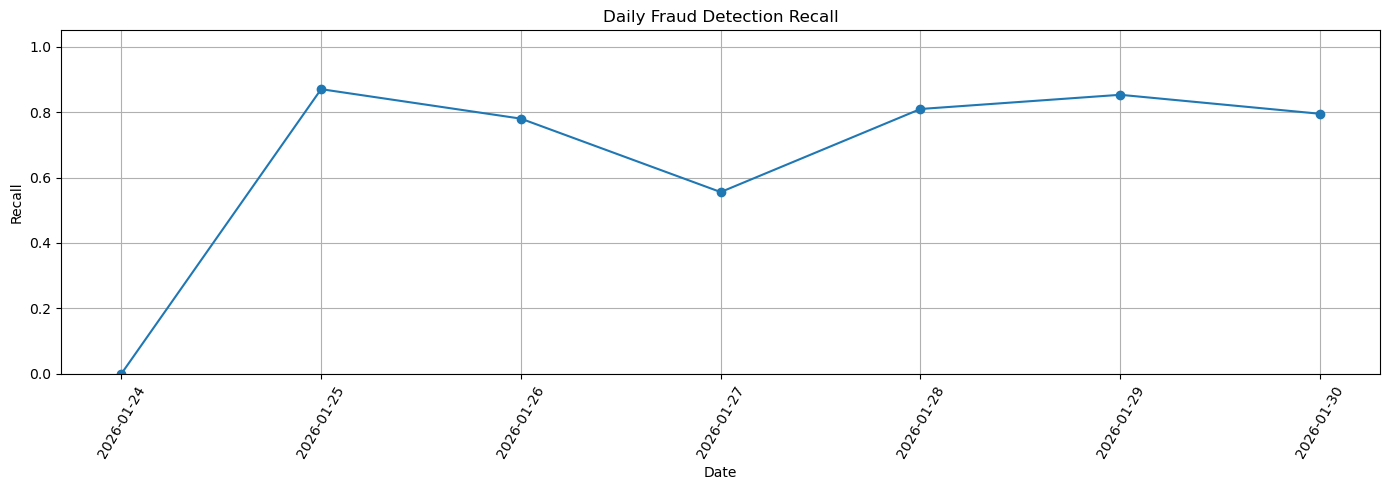

In [28]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_results_df["date"],
    daily_results_df["recall"],
    marker="o"
)

plt.title("Daily Fraud Detection Recall")
plt.xlabel("Date")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.xticks(rotation=60)
plt.grid(True)
plt.tight_layout()
plt.show()

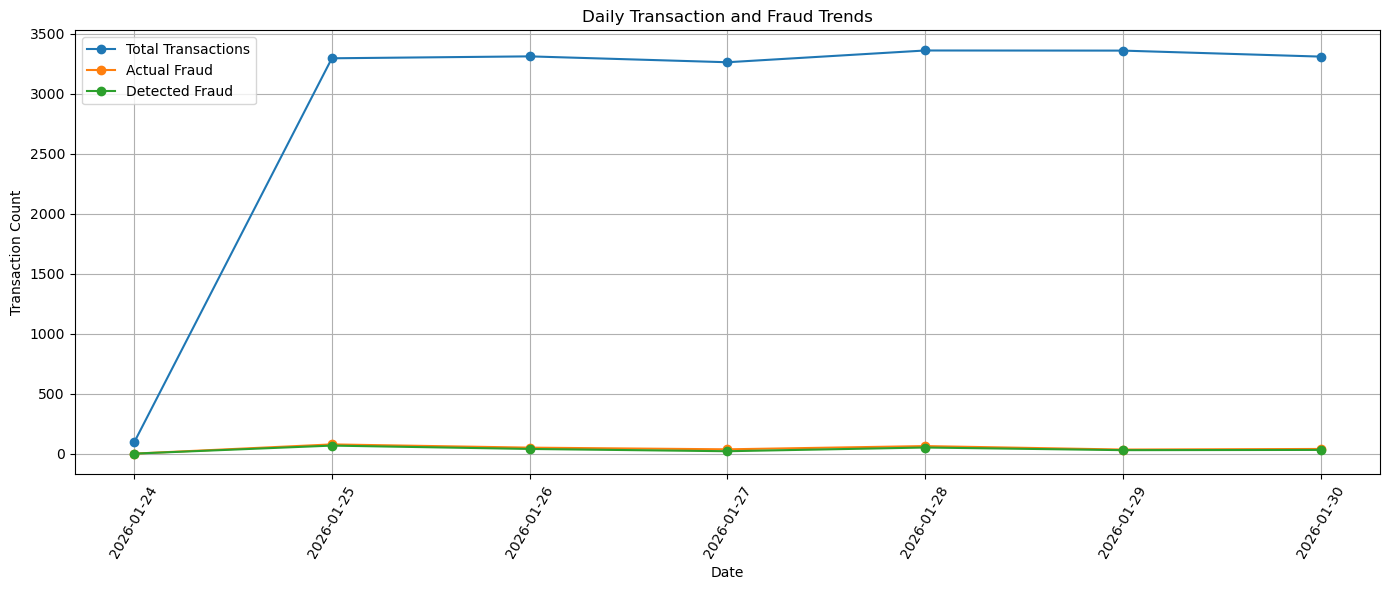

In [29]:
plt.figure(figsize=(14, 6))

plt.plot(
    daily_results_df["date"],
    daily_results_df["transactions"],
    marker="o",
    label="Total Transactions"
)

plt.plot(
    daily_results_df["date"],
    daily_results_df["actual_fraud"],
    marker="o",
    label="Actual Fraud"
)

plt.plot(
    daily_results_df["date"],
    daily_results_df["detected_fraud"],
    marker="o",
    label="Detected Fraud"
)

plt.title("Daily Transaction and Fraud Trends")
plt.xlabel("Date")
plt.ylabel("Transaction Count")
plt.xticks(rotation=60)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
daily_summary = daily_results_df[[
    "transactions",
    "actual_fraud",
    "detected_fraud",
    "missed_fraud",
    "recall"
]].describe()

display(daily_summary.round(4))

,transactions,actual_fraud,detected_fraud,missed_fraud,recall
count,7.0000,7.0000,7.0000,7.0000,7.0000
mean,2856.4286,42.7143,33.8571,8.8571,0.6661
std,1219.0508,24.4930,21.5594,5.1778,0.3116
min,93.0000,0.0000,0.0000,0.0000,0.0000
25%,3279.5000,35.0000,24.5000,6.5000,0.6678
50%,3310.0000,39.0000,31.0000,10.0000,0.7949
75%,3336.0000,56.5000,45.0000,11.5000,0.8312
max,3361.0000,77.0000,67.0000,16.0000,0.8701


In [31]:
import os

os.makedirs("../reports", exist_ok=True)

monthly_results_df.to_csv(
    "../reports/monthly_fraud_analysis.csv",
    index=False
)

daily_results_df.to_csv(
    "../reports/daily_fraud_analysis.csv",
    index=False
)

print("Temporal analysis reports saved!")

Temporal analysis reports saved!


In [32]:
import os

print("Reports directory:")

for file in sorted(os.listdir("../reports")):
    print("-", file)

Reports directory:
- daily_fraud_analysis.csv
- monthly_fraud_analysis.csv


In [33]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Recalculate original model metrics
original_metrics = {
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, y_prob),
    "PR_AUC": average_precision_score(y_test, y_prob)
}

print("=" * 60)
print("REAL-TIME FRAUD DETECTION - FINAL EVALUATION")
print("=" * 60)

print("\nMAIN MODEL: LightGBM")
print(f"Precision: {original_metrics['Precision']:.4f}")
print(f"Recall:    {original_metrics['Recall']:.4f}")
print(f"F1 Score:  {original_metrics['F1']:.4f}")
print(f"ROC-AUC:   {original_metrics['ROC_AUC']:.4f}")
print(f"PR-AUC:    {original_metrics['PR_AUC']:.4f}")

print("\nTEMPORAL ANALYSIS")
print(f"Days analyzed:   {len(daily_results_df)}")
print(f"Months analyzed: {len(monthly_results_df)}")

print("\n" + "=" * 60)
print("EVALUATION COMPLETED")
print("=" * 60)

REAL-TIME FRAUD DETECTION - FINAL EVALUATION

MAIN MODEL: LightGBM
Precision: 0.9222
Recall:    0.7926
F1 Score:  0.8525
ROC-AUC:   0.9988
PR-AUC:    0.9377

TEMPORAL ANALYSIS
Days analyzed:   7
Months analyzed: 1

EVALUATION COMPLETED
